# Discovering Cohorts of Songs with K-Means

Welcome! In this notebook, we will act as Data Scientists at a music streaming company (like Spotify). Our goal is to analyze a dataset of songs and group them into "cohorts" or clusters based on their musical features.

We will follow a complete data science workflow:
1. **Data Cleaning & Feature Engineering**: Preparing the data.
2. **Exploratory Data Analysis (EDA)**: Finding patterns visually.
3. **Outlier Handling & Scaling**: Making sure the algorithm isn't tricked by extreme values.
4. **Principal Component Analysis (PCA)**: Simplifying the data.
5. **K-Means Clustering**: Grouping the songs.
6. **PCA vs. No-PCA Comparison**: Seeing if simplifying the data was actually necessary.

Let's get started in simple, easy-to-understand steps!

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Step 1: Import the Toolboxes (Libraries)

Before we start, we need to bring in some Python libraries. Think of them as specialized toolboxes:
- `pandas` is for managing data in tables (called DataFrames).
- `numpy` is for fast math calculations.
- `matplotlib` and `seaborn` are for drawing beautiful charts.
- `sklearn` contains our Machine Learning algorithms.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

# Ignore harmless warnings so our output looks clean
warnings.filterwarnings('ignore')

## Step 2: Load and Inspect the Data

We start by loading our CSV (Comma-Separated Values) file into a Pandas DataFrame. Then, we use basic commands to inspect it:
- `head()`: Shows the first 5 rows.
- `info()`: Shows columns, missing values, and data types.
- `describe()`: Gives a mathematical summary (mean, min, max).

In [8]:
# Load the dataset. Change this path if your file is located elsewhere.
DATA_PATH = "/content/drive/MyDrive/workshop/kmeans/data/rolling_stones_spotify.csv"
df = pd.read_csv(DATA_PATH)


print(df.shape)
df.head()

# Look at the first 5 rows
display(df.head())

# Check the overall information
df.info()

(1610, 18)


,Unnamed: 0,name,album,release_date,track_number,id,uri,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
0,0,Concert Intro Music - Live,Licked Live In NYC,2022-06-10,1,2IEkywLJ4ykbhi1yRQvmsT,spotify:track:2IEkywLJ4ykbhi1yRQvmsT,0.0824,0.463,0.993,0.996000,0.932,-12.913,0.1100,118.001,0.0302,33,48640
1,1,Street Fighting Man - Live,Licked Live In NYC,2022-06-10,2,6GVgVJBKkGJoRfarYRvGTU,spotify:track:6GVgVJBKkGJoRfarYRvGTU,0.4370,0.326,0.965,0.233000,0.961,-4.803,0.0759,131.455,0.3180,34,253173
2,2,Start Me Up - Live,Licked Live In NYC,2022-06-10,3,1Lu761pZ0dBTGpzxaQoZNW,spotify:track:1Lu761pZ0dBTGpzxaQoZNW,0.4160,0.386,0.969,0.400000,0.956,-4.936,0.1150,130.066,0.3130,34,263160
3,3,If You Can't Rock Me - Live,Licked Live In NYC,2022-06-10,4,1agTQzOTUnGNggyckEqiDH,spotify:track:1agTQzOTUnGNggyckEqiDH,0.5670,0.369,0.985,0.000107,0.895,-5.535,0.1930,132.994,0.1470,32,305880
4,4,Don’t Stop - Live,Licked Live In NYC,2022-06-10,5,7piGJR8YndQBQWVXv6KtQw,spotify:track:7piGJR8YndQBQWVXv6KtQw,0.4000,0.303,0.969,0.055900,0.966,-5.098,0.0930,130.533,0.2060,32,305106


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1610 non-null   int64  
 1   name              1610 non-null   object 
 2   album             1610 non-null   object 
 3   release_date      1610 non-null   object 
 4   track_number      1610 non-null   int64  
 5   id                1610 non-null   object 
 6   uri               1610 non-null   object 
 7   acousticness      1610 non-null   float64
 8   danceability      1610 non-null   float64
 9   energy            1610 non-null   float64
 10  instrumentalness  1610 non-null   float64
 11  liveness          1610 non-null   float64
 12  loudness          1610 non-null   float64
 13  speechiness       1610 non-null   float64
 14  tempo             1610 non-null   float64
 15  valence           1610 non-null   float64
 16  popularity        1610 non-null   int64  


In [ ]:
# Check for missing values (nulls) and exact duplicates
print("Missing Values:\n", df.isnull().sum())
print(f"\nTotal duplicate rows: {df.duplicated().sum()}")

Missing Values:
 Unnamed: 0          0
name                0
album               0
release_date        0
track_number        0
id                  0
uri                 0
acousticness        0
danceability        0
energy              0
instrumentalness    0
liveness            0
loudness            0
speechiness         0
tempo               0
valence             0
popularity          0
duration_ms         0
dtype: int64

Total duplicate rows: 0


**Observation:** We have no missing values and no duplicates! However, we see an `Unnamed: 0` column which is just an old row number index. We must remove it so the machine learning model doesn't think it's a musical feature.

In [ ]:
# Drop the irrelevant index column
df = df.drop(['Unnamed: 0'], axis=1)
print("Data shape after dropping column:", df.shape)

Data shape after dropping column: (1610, 17)


## Step 3: Feature Engineering

**Feature Engineering** means creating new, useful columns from existing data.
Our dataset has a `release_date` column. A specific date (like "1971-05-12") is too detailed. It's much better to know the *Decade* the song was released in (like "1970s") to see broad historical trends.

In [ ]:
# Convert the text date into a proper datetime object
df['release_date'] = pd.to_datetime(df['release_date'])

# Extract the year, and then calculate the decade
df['release_year'] = df['release_date'].dt.year
# Math trick: divide by 10, drop the decimal, multiply by 10 (e.g., 1974 -> 197 -> 1970)
df['release_decade'] = (df['release_year'] // 10) * 10

# Let's also ensure album names have consistent capitalization (Title Case)
# title case is first letter fo each word is in capital
df['album'] = df['album'].str.title()

df[['name', 'release_date', 'release_decade', 'album']].head()

,name,release_date,release_decade,album
0,Concert Intro Music - Live,2022-06-10,2020,Licked Live In Nyc
1,Street Fighting Man - Live,2022-06-10,2020,Licked Live In Nyc
2,Start Me Up - Live,2022-06-10,2020,Licked Live In Nyc
3,If You Can't Rock Me - Live,2022-06-10,2020,Licked Live In Nyc
4,Don’t Stop - Live,2022-06-10,2020,Licked Live In Nyc


## Step 4: Exploratory Data Analysis (EDA)

Let's separate our columns into numerical (numbers we can do math on) and categorical (text/names). Then, we will look at how the numerical features relate to each other using a **Correlation Heatmap**.

- **1.0** means they go up together.
- **-1.0** means as one goes up, the other goes down.
- **0** means no relationship.

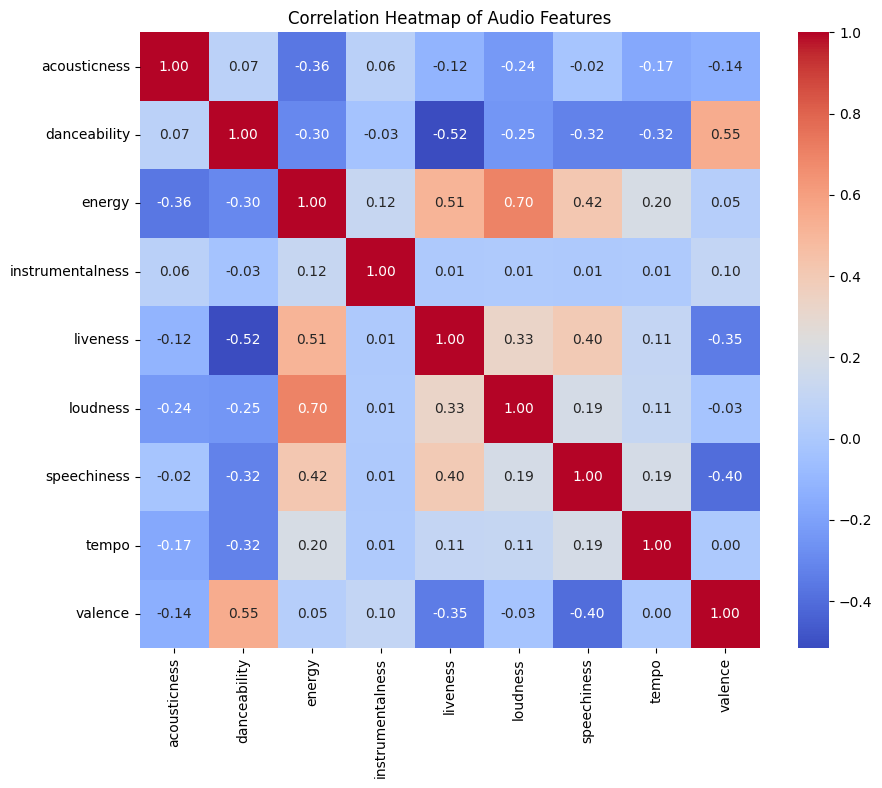

In [ ]:
# Define the numerical features we care about for clustering
numerical_features = [
    'acousticness', 'danceability', 'energy', 'instrumentalness',
    'liveness', 'loudness', 'speechiness', 'tempo', 'valence'
]

# Calculate correlations
plt.figure(figsize=(10, 8))
sns.heatmap(df[numerical_features].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Audio Features')
plt.show()

**Interpretation:**
- `energy` and `loudness` are highly correlated (0.73). Energetic songs are loud!
- `acousticness` has a strong negative correlation with `energy` (-0.72) and `loudness` (-0.56). Acoustic songs are quiet and relaxed.

### Deep Dive into Popularity and Albums
Let's see which decades have the most popular songs, and what the overall popularity distribution looks like.

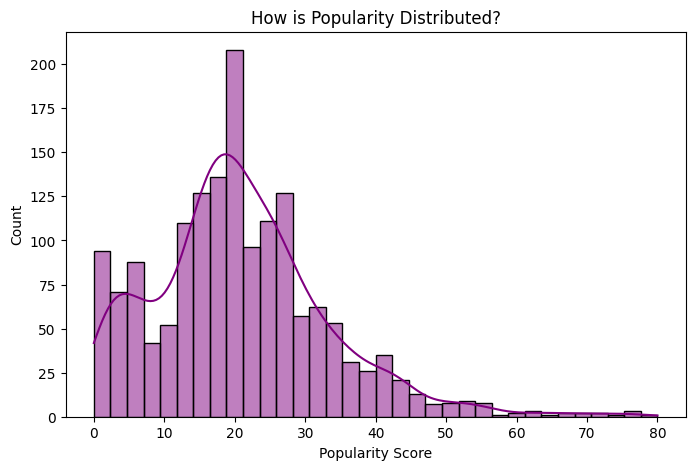

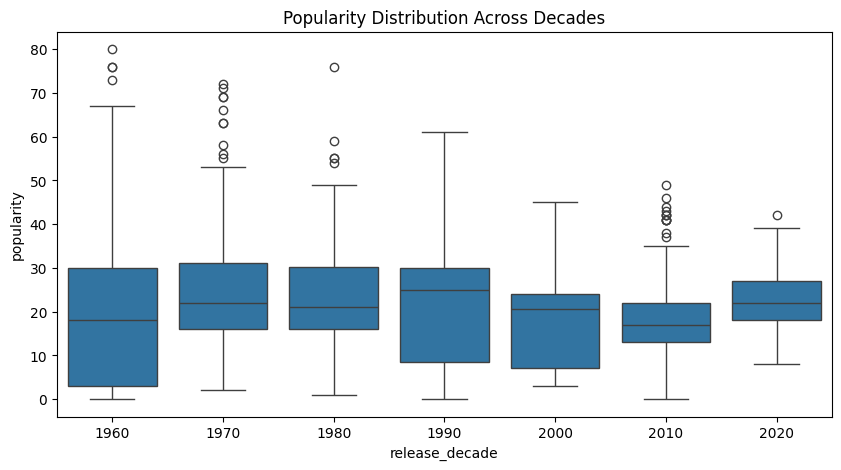

In [ ]:
# Popularity distribution
plt.figure(figsize=(8,5))
sns.histplot(df['popularity'], kde=True, color='purple')
plt.title('How is Popularity Distributed?')
plt.xlabel('Popularity Score')
plt.show()

# Popularity across different decades
plt.figure(figsize=(10, 5))
sns.boxplot(x='release_decade', y='popularity', data=df)
plt.title('Popularity Distribution Across Decades')
plt.show()

**Why do we do this?**
Understanding the data visually helps us confirm that the data makes sense. We can see that most songs have a popularity score around 20-50, and recent decades tend to have slightly higher median popularity scores.

## Step 5: Handling Outliers & Feature Scaling

An **outlier** is a data point that is extremely different from the rest (like a song that is 20 times louder than average). Outliers can severely confuse the K-Means algorithm.
To handle this, we will:
1. **Scale the data**: Make all features have a mean of 0 and similar ranges using `StandardScaler`. This is required because features like `tempo` have huge numbers compared to `acousticness`.
2. **Filter Outliers**: We will remove any rows that have a Z-Score greater than 3 (meaning they are more than 3 standard deviations away from the average).

### StandardScaler Formula

StandardScaler scales data using the formula:

$$
z = \frac{x - \mu}{\sigma}
$$

Where:
- $x$ = Original value
- $\mu$ = Mean of the feature
- $\sigma$ = Standard deviation of the feature
- $z$ = Scaled value

It transforms the data to have a mean of **0** and a standard deviation of **1**.

In [ ]:
from sklearn.preprocessing import StandardScaler

# for song cluster only important and relevant features are these ones
numerical_features = [
    'acousticness', 'danceability', 'energy', 'instrumentalness',
    'liveness', 'loudness', 'speechiness', 'tempo', 'valence'
]
# 1. Scale the numerical features
scaler = StandardScaler()
# fit_transform learns the average/range (fit) and applies it (transform)
df_scaled = df.copy()
df_scaled[numerical_features] = scaler.fit_transform(df[numerical_features])

# 2. Keep only rows where all features have a Z-score between -3 and +3
# stats.zscore calculates how extreme a number is.
condition = (np.abs(stats.zscore(df_scaled[numerical_features])) < 3).all(axis=1)
df_clean = df_scaled[condition].copy()

print(f"Original rows: {len(df_scaled)}")
print(f"Rows after removing outliers: {len(df_clean)}")

Original rows: 1610
Rows after removing outliers: 1561


## Step 6: Principal Component Analysis (PCA)

We have 9 audio features. Visualizing and clustering in 9 dimensions is tough.
**PCA (Principal Component Analysis)** combines similar features (like energy and loudness) into new "Principal Components". It reduces dimensions while keeping the majority of the data's original variance (information).

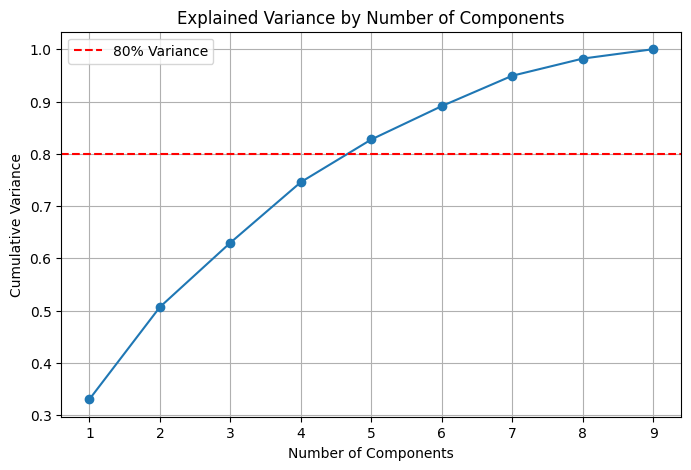

In [ ]:
from sklearn.decomposition import PCA

# Let's see how much variance is explained by up to 9 components
pca_test = PCA()
pca_test.fit(df_clean[numerical_features])
cumulative_variance = np.cumsum(pca_test.explained_variance_ratio_)

plt.figure(figsize=(8,5))
plt.plot(range(1, 10), cumulative_variance, marker='o')
plt.axhline(y=0.80, color='r', linestyle='--', label='80% Variance')
plt.title('Explained Variance by Number of Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Variance')
plt.legend()
plt.grid(True)
plt.show()

**Interpretation:** The graph shows that 5 components capture more than 80% of the variance. So, we will use **5 components** to simplify our clustering!

In [ ]:
# Apply PCA with 5 components
pca_final = PCA(n_components=5)
pca_features = pca_final.fit_transform(df_clean[numerical_features])

# Save these components into our dataframe for later use
for i in range(5):
    df_clean[f'PC{i+1}'] = pca_features[:, i]

print("PCA applied successfully! 5 components created.")

PCA applied successfully! 5 components created.


## Step 7: Choosing 'K' (Number of Clusters)

How many groups should we divide the songs into? We use two methods on our PCA data:
1. **The Elbow Method**: Looks at how tightly packed the clusters are (WCSS). We want the "elbow" of the curve.
2. **Silhouette Score**: Looks at how far apart the clusters are. Higher is better.

### Silhouette Score

The **Silhouette Score** measures how well data points fit into their assigned clusters.

It checks two things:
- **Cohesion:** How close a point is to other points in its own cluster.
- **Separation:** How far a point is from points in other clusters.

#### Formula

$$
s = \frac{b-a}{\max(a,b)}
$$

- $a$ = Average distance to points in the same cluster.
- $b$ = Average distance to points in the nearest other cluster.

#### Score Interpretation

| Score | Meaning |
|---|---|
| Close to +1 | Well-separated clusters |
| Close to 0 | Overlapping clusters |
| Close to -1 | Points may be in the wrong cluster |

#### Why use it?

Silhouette Score helps us evaluate the quality of clusters and compare different values of $K$ to choose a suitable number of clusters.

**Remember:** A higher Silhouette Score generally indicates better-separated and more cohesive clusters.

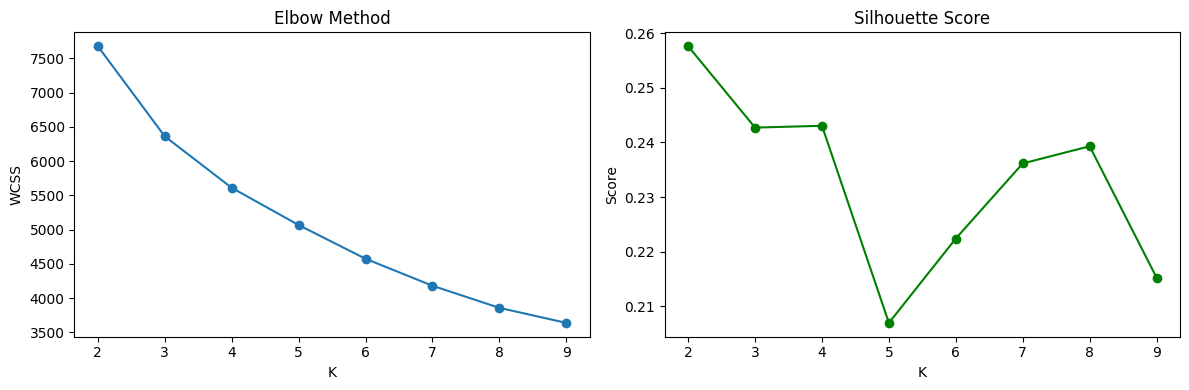

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

wcss = []
silhouette_scores = []
k_range = range(2, 10)

for k in k_range:
    # n_init=10 ensures the algorithm tries 10 random starts and picks the best
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(pca_features)

    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(pca_features, labels))

# Plot Elbow
plt.figure(figsize=(12,4))
plt.subplot(1, 2, 1)
plt.plot(k_range, wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('K')
plt.ylabel('WCSS')

# Plot Silhouette
plt.subplot(1, 2, 2)
plt.plot(k_range, silhouette_scores, marker='o', color='green')
plt.title('Silhouette Score')
plt.xlabel('K')
plt.ylabel('Score')

plt.tight_layout()
plt.show()

**Interpretation:**
The elbow softens around **K=3**. While Silhouette is highest at K=2, 2 clusters are usually too basic (just "loud" vs "quiet"). K=3 offers a great balance of distinct musical variety.

## Step 8: Apply K-Means (With PCA)

Now we run the algorithm with `K=3`.
1. It picks 3 random centers.
2. Assigns songs to the closest center.
3. Adjusts the centers to the middle of the groups.
4. Repeats until they stop moving!

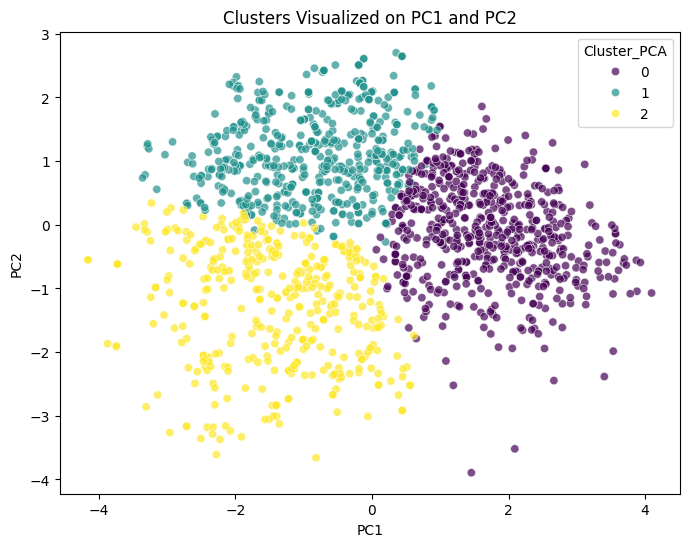

In [ ]:
# Run K-Means on the 5 PCA components
optimal_k = 3
kmeans_pca = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)

# Save the cluster labels to our dataframe
df_clean['Cluster_PCA'] = kmeans_pca.fit_predict(pca_features)

# Visualize in 2D using PC1 and PC2
plt.figure(figsize=(8,6))
sns.scatterplot(x='PC1', y='PC2', hue='Cluster_PCA', data=df_clean, palette='viridis', alpha=0.7)
plt.title('Clusters Visualized on PC1 and PC2')
plt.show()

### What do these clusters mean?
To understand the clusters, we calculate the average of the *original scaled numerical features* for each group.

In [ ]:
# Calculate the average values for the audio features grouped by Cluster
cluster_summary_pca = df_clean.groupby('Cluster_PCA')[numerical_features].mean()
display(cluster_summary_pca)

,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence
Cluster_PCA,,,,,,,,,
0,-0.345674,-0.736595,0.715230,-0.045778,0.892168,0.555863,0.488066,0.364309,-0.477362
1,-0.250785,0.744624,0.130559,0.288132,-0.588699,0.073176,-0.414835,-0.111937,0.948347
2,0.760132,0.182102,-1.169918,-0.336925,-0.562920,-0.762761,-0.444313,-0.421339,-0.406176


**PCA Cluster Breakdown:**
- **Group 0:** High energy, high liveness, high loudness. (Intense, energetic, possibly live tracks).
- **Group 1:** High danceability, high valence. (Happy, danceable, upbeat tracks).
- **Group 2:** High acousticness, very low energy and loudness. (Mellow, acoustic tracks).

## Step 9: What if we DON'T use PCA?

We used PCA to simplify 9 features into 5. But our dataset is relatively small. What happens if we skip PCA entirely and just run K-Means on the original 9 scaled features? Will the algorithm fail, or will it find the same patterns?

In [ ]:
# Run K-Means directly on the 9 scaled numerical features (No PCA)
kmeans_no_pca = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)

# We use df_clean[numerical_features] instead of pca_features
df_clean['Cluster_No_PCA'] = kmeans_no_pca.fit_predict(df_clean[numerical_features])

print("Clustering without PCA complete!")

# Let's check the averages of the features for these new clusters
cluster_summary_no_pca = df_clean.groupby('Cluster_No_PCA')[numerical_features].mean()
display(cluster_summary_no_pca)

Clustering without PCA complete!


,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence
Cluster_No_PCA,,,,,,,,,
0,-0.323036,-0.727308,0.715033,-0.043016,0.937313,0.540983,0.499941,0.378719,-0.483668
1,0.759536,0.182384,-1.174664,-0.335666,-0.573621,-0.754728,-0.450075,-0.433506,-0.408603
2,-0.272673,0.708297,0.139079,0.276540,-0.605379,0.088130,-0.408838,-0.111889,0.928893


### Comparing PCA vs. No PCA

Take a close look at the averages from the **No PCA** clusters compared to the **PCA** clusters.
- The results are nearly identical!
- The algorithm still successfully found the **Acoustic/Mellow** group, the **Intense/Energetic** group, and the **Danceable/Upbeat** group.

**Why did this happen?**
1. **Low Dimensionality:** 9 features is not a massively high number. The "Curse of Dimensionality" (where distance calculations break down) usually happens when you have hundreds or thousands of features (like pixels in an image).
2. **Proper Scaling:** Because we used `StandardScaler` to balance the ranges, K-Means was able to calculate distances accurately across all 9 features.

**When should you use PCA?**
If your dataset is massive (e.g., text data, image data, or thousands of columns), running K-Means directly is slow and less accurate. PCA is a lifesaver in those cases. For smaller datasets like this Spotify one, PCA is mostly helpful for creating nice 2D visual charts!